# Unsupervised Learning — Steel Plates Faults

Notebook Person 4: clustering dengan fitur numerik tanpa memakai label fault saat proses clustering.

**Tujuan:** preprocessing, membandingkan K-Means/Agglomerative/DBSCAN, evaluasi metrik, PCA, dan interpretasi cluster.

Jalankan dari root repository atau folder `notebooks/`. Dataset dan `src/data_pipeline.py` harus tersedia.

## 1. Import library dan konfigurasi

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
ROOT = Path("/mnt/data/steel_run")
RAW = ROOT / "data" / "raw" / "faults.csv"
FEATURES = ['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas']
FAULT_TYPES = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']
print("Project root:", ROOT)
print("Raw data path:", RAW)

from IPython.display import display


Project root: /mnt/data/steel_run
Raw data path: /mnt/data/steel_run/data/raw/faults.csv


**Penjelasan:** Mengimpor pustaka dan konfigurasi fitur/path dari pipeline project agar konsisten dengan notebook anggota tim lain.

## 2. Memuat data dan memisahkan fitur

In [2]:
df = pd.read_csv(RAW)
df.columns = df.columns.str.strip()
if "K_Scratch" in df.columns and "K_Scatch" not in df.columns:
    df = df.rename(columns={"K_Scratch": "K_Scatch"})
missing_features = [c for c in FEATURES if c not in df.columns]
if missing_features:
    raise ValueError(f"Kolom fitur tidak ditemukan: {missing_features}")
X = df[FEATURES].copy()
available_fault_types = [c for c in FAULT_TYPES if c in df.columns]
print("Ukuran dataset:", df.shape)
print("Jumlah fitur clustering:", len(FEATURES))
print("Kolom label fault tersedia:", available_fault_types)
display(df.head())


Ukuran dataset: (1941, 34)
Jumlah fitur clustering: 27
Kolom label fault tersedia: ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


**Penjelasan:** Clustering hanya memakai `FEATURES`. Label fault tidak dipakai untuk membentuk cluster; jika tersedia, label hanya boleh dipakai untuk interpretasi setelahnya.

## 3. Pemeriksaan awal data

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1941 non-null   int64  
 1   X_Maximum              1941 non-null   int64  
 2   Y_Minimum              1941 non-null   int64  
 3   Y_Maximum              1941 non-null   int64  
 4   Pixels_Areas           1941 non-null   int64  
 5   X_Perimeter            1941 non-null   int64  
 6   Y_Perimeter            1941 non-null   int64  
 7   Sum_of_Luminosity      1941 non-null   int64  
 8   Minimum_of_Luminosity  1941 non-null   int64  
 9   Maximum_of_Luminosity  1941 non-null   int64  
 10  Length_of_Conveyer     1941 non-null   int64  
 11  TypeOfSteel_A300       1941 non-null   int64  
 12  TypeOfSteel_A400       1941 non-null   int64  
 13  Steel_Plate_Thickness  1941 non-null   int64  
 14  Edges_Index            1941 non-null 

,count,mean,std,min,25%,50%,75%,max
X_Minimum,1941.0,5.711360e+02,5.206907e+02,0.0000,51.0000,4.350000e+02,1.053000e+03,1.705000e+03
X_Maximum,1941.0,6.179645e+02,4.976274e+02,4.0000,192.0000,4.670000e+02,1.072000e+03,1.713000e+03
Y_Minimum,1941.0,1.650685e+06,1.774578e+06,6712.0000,471253.0000,1.204128e+06,2.183073e+06,1.298766e+07
Y_Maximum,1941.0,1.650739e+06,1.774590e+06,6724.0000,471281.0000,1.204136e+06,2.183084e+06,1.298769e+07
Pixels_Areas,1941.0,1.893878e+03,5.168460e+03,2.0000,84.0000,1.740000e+02,8.220000e+02,1.526550e+05
X_Perimeter,1941.0,1.118552e+02,3.012092e+02,2.0000,15.0000,2.600000e+01,8.400000e+01,1.044900e+04
Y_Perimeter,1941.0,8.296600e+01,4.264829e+02,1.0000,13.0000,2.500000e+01,8.300000e+01,1.815200e+04
Sum_of_Luminosity,1941.0,2.063121e+05,5.122936e+05,250.0000,9522.0000,1.920200e+04,8.301100e+04,1.159141e+07
Minimum_of_Luminosity,1941.0,8.454869e+01,3.213428e+01,0.0000,63.0000,9.000000e+01,1.060000e+02,2.030000e+02
Maximum_of_Luminosity,1941.0,1.301937e+02,1.869099e+01,37.0000,124.0000,1.270000e+02,1.400000e+02,2.530000e+02


Missing values per fitur:


Series([], dtype: int64)

Jumlah baris duplikat: 0


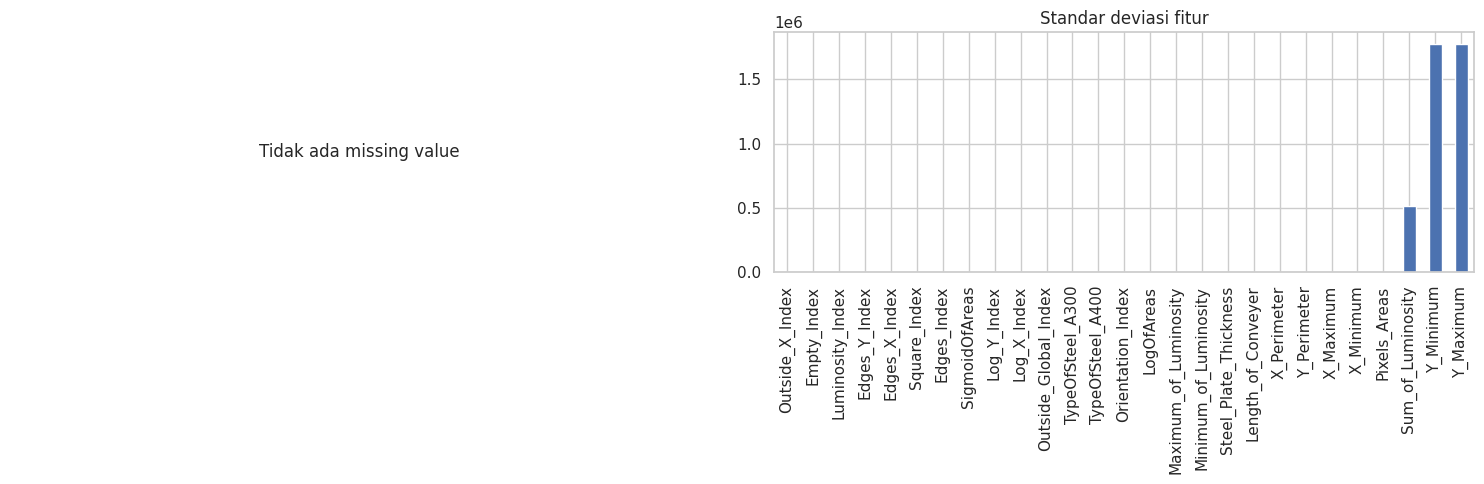

In [3]:
print("Informasi dataset:")
df.info()
print("Statistik deskriptif fitur:")
display(X.describe().T)
missing_counts = X.isna().sum().sort_values(ascending=False)
print("Missing values per fitur:")
display(missing_counts[missing_counts > 0])
print("Jumlah baris duplikat:", int(df.duplicated().sum()))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
if (missing_counts > 0).any():
    missing_counts[missing_counts > 0].sort_values().plot(kind="barh", ax=axes[0], title="Missing values per fitur")
if (missing_counts > 0).sum() == 0:
    axes[0].text(0.5, 0.5, "Tidak ada missing value", ha="center", va="center")
    axes[0].set_axis_off()
X.std(numeric_only=True).sort_values().plot(kind="bar", ax=axes[1], title="Standar deviasi fitur")
axes[1].tick_params(axis="x", labelrotation=90)
plt.tight_layout()
plt.show()


**Penjelasan:** Pemeriksaan ini mengungkap missing value, duplikasi, statistik fitur, dan perbedaan skala yang penting untuk algoritma berbasis jarak.

## 4. Preprocessing

In [4]:
X_numeric = X.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
all_empty = X_numeric.columns[X_numeric.isna().all()].tolist()
if all_empty:
    print("Fitur seluruhnya kosong dikeluarkan:", all_empty)
    X_numeric = X_numeric.drop(columns=all_empty)
imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(imputer.fit_transform(X_numeric), columns=X_numeric.columns, index=X_numeric.index)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_imputed), columns=X_imputed.columns, index=X_imputed.index)
assert np.isfinite(X_scaled.to_numpy()).all(), "Masih ada nilai non-finite."
print("Jumlah baris:", len(X_scaled))
print("Jumlah fitur setelah preprocessing:", X_scaled.shape[1])
display(X_scaled.head())


Jumlah baris: 1941
Jumlah fitur setelah preprocessing: 27


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
0,-1.016481,-1.141639,-0.777729,-0.777729,-0.314852,-0.314996,-0.091389,-0.355537,-0.266099,-1.187708,1.576303,1.223956,-1.223956,0.022920,-0.940864,-1.258531,-1.435364,-0.486227,-0.575331,0.796401,0.879804,-0.083538,-0.898437,0.528872,1.467656,-1.075752,-0.009490
1,0.141894,0.066403,0.500188,0.500171,-0.345623,-0.338242,-0.124225,-0.380574,-0.017079,-0.384975,1.576303,1.223956,-1.223956,0.022920,1.445043,-0.254349,-1.342740,-0.504888,-0.043290,0.654223,0.879804,-0.581936,-1.157841,0.130174,1.417530,-0.297824,-0.845759
2,0.495362,0.436253,-0.054546,-0.054566,-0.352784,-0.344883,-0.150024,-0.387261,0.449832,-0.277944,1.133521,1.223956,-1.223956,0.386082,2.133548,-0.521791,-0.876299,-0.503191,0.573451,0.571820,0.879804,-0.812814,-1.157841,-0.325764,1.165103,0.057185,-1.091513
3,0.541467,0.486504,-0.722225,-0.722225,-0.332463,-0.328279,-0.089044,-0.365736,0.449832,-0.224429,-0.734467,-0.817023,0.817023,3.836121,1.324897,0.197460,-1.532047,-0.477744,-0.296153,0.796401,0.879804,-0.313021,-1.018897,0.550227,1.519978,-0.171419,-0.189237
4,1.379032,1.382988,-0.649678,-0.649559,0.099692,-0.172201,0.415209,0.079307,-1.480069,-0.224429,-0.734467,-0.817023,0.817023,1.929520,-0.875117,0.250657,-1.861950,-0.352206,-1.345434,0.747301,0.879804,1.127655,-0.218461,2.216130,1.698514,-0.456503,1.221636


**Penjelasan:** Nilai non-numerik/tak hingga menjadi missing value, lalu diisi median. StandardScaler menyamakan skala fitur. Fitur yang seluruhnya kosong dikeluarkan.

## 5. K-Means — Elbow Method

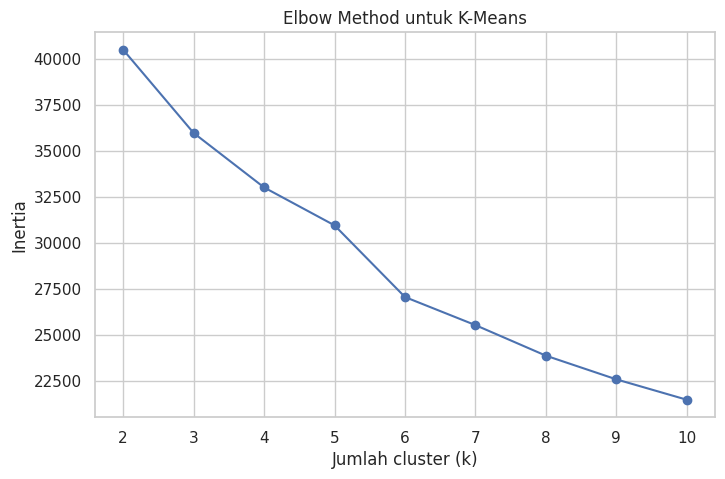

In [5]:
k_values = list(range(2, min(10, len(X_scaled) - 1) + 1))
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method untuk K-Means")
plt.xticks(k_values)
plt.show()


**Penjelasan:** Inertia mengukur jumlah kuadrat jarak titik ke centroid. Kandidat k dapat dipilih di sekitar titik saat penurunan inertia mulai melambat.

## 6. K-Means — Silhouette Score

,k,silhouette
0,2,0.303229
1,3,0.191122
2,4,0.194335
3,5,0.195560
4,6,0.197171
5,7,0.196886
6,8,0.205956
7,9,0.202954
8,10,0.207513


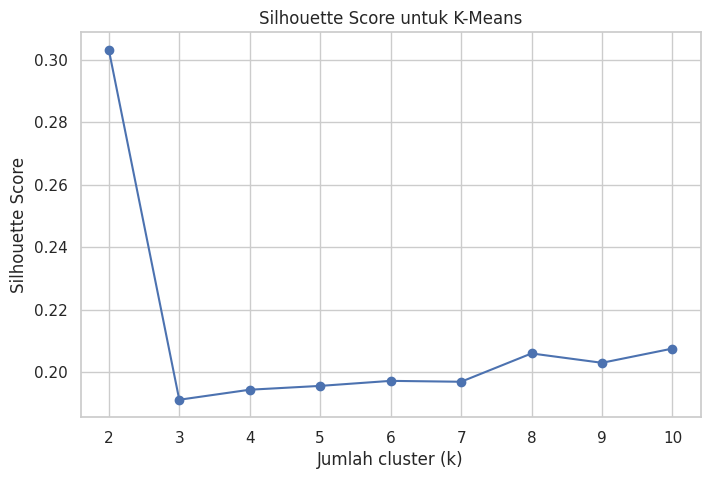

k terpilih berdasarkan Silhouette Score: 2


In [6]:
silhouette_by_k = {}
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_k = model.fit_predict(X_scaled)
    if len(np.unique(labels_k)) > 1:
        silhouette_by_k[k] = silhouette_score(X_scaled, labels_k)
silhouette_k_df = pd.DataFrame({"k": list(silhouette_by_k.keys()), "silhouette": list(silhouette_by_k.values())})
display(silhouette_k_df)
plt.figure(figsize=(8, 5))
plt.plot(silhouette_k_df["k"], silhouette_k_df["silhouette"], marker="o")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score untuk K-Means")
plt.xticks(k_values)
plt.show()
if not silhouette_by_k:
    raise ValueError("Tidak ada nilai k yang menghasilkan beberapa cluster.")
optimal_k = max(silhouette_by_k, key=silhouette_by_k.get)
print("k terpilih berdasarkan Silhouette Score:", optimal_k)


**Penjelasan:** Silhouette lebih tinggi umumnya menunjukkan pemisahan cluster yang lebih baik. k dipilih berdasarkan skor tertinggi pada rentang uji, lalu ditinjau bersama Elbow dan konteks masalah.

## 7. K-Means dan profil cluster

Jumlah data per cluster K-Means:


KMeans_Cluster
0     390
1    1551
Name: jumlah_data, dtype: int64

Rata-rata fitur pada skala asli per cluster:


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
KMeans_Cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,102.858974,273.030769,1.828636e+06,1.828792e+06,8344.512821,430.156410,287.248718,911260.420513,46.456410,132.282051,1388.294872,0.056410,0.943590,47.805128,0.109423,0.494578,0.536759,0.123008,0.503809,0.474465,0.279487,3.809195,2.172890,1.950589,-0.313618,-0.154075,0.999719
1,688.884591,704.698259,1.605939e+06,1.605967e+06,271.862025,31.818182,31.598968,29052.427466,94.127015,129.668601,1476.979368,0.486783,0.513217,86.515796,0.387611,0.393993,0.579318,0.010819,0.637363,0.898716,0.650226,2.161276,1.125171,1.265648,0.183090,-0.125580,0.481245


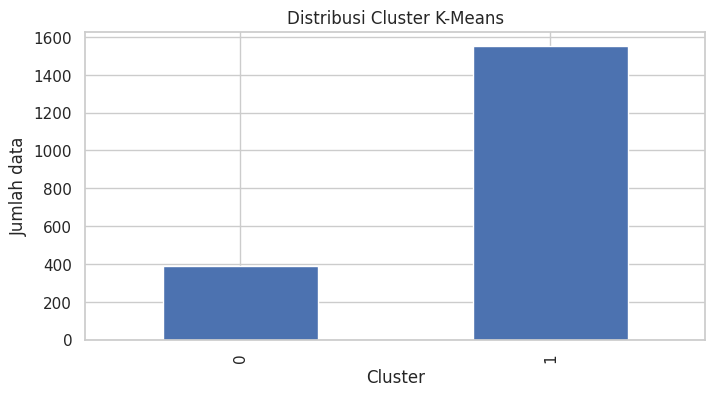

In [7]:
kmeans = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)
clustered = X_imputed.copy()
clustered["KMeans_Cluster"] = labels_kmeans
print("Jumlah data per cluster K-Means:")
display(clustered["KMeans_Cluster"].value_counts().sort_index().rename("jumlah_data"))
print("Rata-rata fitur pada skala asli per cluster:")
kmeans_profile = clustered.groupby("KMeans_Cluster")[X_imputed.columns].mean()
display(kmeans_profile)
clustered["KMeans_Cluster"].value_counts().sort_index().plot(kind="bar", figsize=(8, 4), title="Distribusi Cluster K-Means")
plt.xlabel("Cluster")
plt.ylabel("Jumlah data")
plt.show()


**Penjelasan:** Profil rata-rata memakai fitur yang sudah diimputasi tetapi belum distandardisasi agar satuan fitur lebih mudah ditafsirkan. Cluster bukan otomatis jenis kerusakan tertentu.

## 8. Agglomerative Clustering

In [8]:
agglomerative = AgglomerativeClustering(n_clusters=optimal_k, linkage="ward")
labels_agg = agglomerative.fit_predict(X_scaled)
clustered["Agglomerative_Cluster"] = labels_agg
print("Jumlah data per cluster Agglomerative:")
display(clustered["Agglomerative_Cluster"].value_counts().sort_index().rename("jumlah_data"))
agg_profile = clustered.groupby("Agglomerative_Cluster")[X_imputed.columns].mean()
display(agg_profile)


Jumlah data per cluster Agglomerative:

Agglomerative_Cluster
0     334
1    1607
Name: jumlah_data, dtype: int64

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
Agglomerative_Cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,63.796407,249.529940,1.906992e+06,1.907150e+06,9255.245509,464.730539,303.209581,1.010606e+06,40.556886,132.236527,1383.940120,0.041916,0.958084,42.485030,0.083453,0.481243,0.556371,0.134574,0.522053,0.450824,0.221557,3.889070,2.234066,1.954747,-0.389488,-0.157343,1.000000
1,676.581829,694.540137,1.597414e+06,1.597446e+06,363.886745,38.513379,37.190417,3.914713e+04,93.691973,129.769135,1474.794026,0.474798,0.525202,86.272558,0.383314,0.400270,0.573759,0.012325,0.628918,0.888845,0.649347,2.202101,1.148966,1.288652,0.181550,-0.125893,0.499254


**Penjelasan:** Agglomerative menggabungkan kelompok secara bertahap. Linkage Ward berusaha menjaga kenaikan variasi dalam cluster tetap kecil.

## 9. DBSCAN — pencarian parameter

In [9]:
dbscan_candidates = []
for eps in [1.5, 2.0, 2.5, 3.0]:
    for min_samples in [5, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        non_noise = labels != -1
        n_clusters = len(set(labels[non_noise]))
        score = np.nan
        if n_clusters >= 2 and non_noise.sum() > n_clusters:
            score = silhouette_score(X_scaled.loc[non_noise], labels[non_noise])
        dbscan_candidates.append({"eps": eps, "min_samples": min_samples,
            "jumlah_cluster_non_noise": n_clusters,
            "noise_percent": 100 * np.mean(labels == -1),
            "silhouette_non_noise": score})
dbscan_search = pd.DataFrame(dbscan_candidates).sort_values("silhouette_non_noise", ascending=False, na_position="last")
display(dbscan_search)
valid = dbscan_search.dropna(subset=["silhouette_non_noise"])
if not valid.empty:
    best = valid.iloc[0]
    best_eps, best_min_samples = float(best["eps"]), int(best["min_samples"])
else:
    best_eps, best_min_samples = 2.0, 5
labels_dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples).fit_predict(X_scaled)
clustered["DBSCAN_Cluster"] = labels_dbscan
print(f"Parameter DBSCAN terpilih: eps={best_eps}, min_samples={best_min_samples}")
display(clustered["DBSCAN_Cluster"].value_counts().sort_index().rename("jumlah_data; -1 berarti noise"))


,eps,min_samples,jumlah_cluster_non_noise,noise_percent,silhouette_non_noise
1,1.5,10,15,74.085523,0.548159
0,1.5,5,36,54.301906,0.339996
3,2.0,10,12,40.236991,0.267633
7,3.0,10,4,6.852138,0.171583
5,2.5,10,8,17.877383,0.161241
6,3.0,5,6,4.533745,0.136451
4,2.5,5,13,10.664606,0.106372
2,2.0,5,26,25.914477,0.072421


Parameter DBSCAN terpilih: eps=1.5, min_samples=10


DBSCAN_Cluster
-1     1438
 0       14
 1       33
 2       20
 3       28
 4       12
 5       11
 6       64
 7       34
 8      173
 9       13
 10      21
 11      19
 12      17
 13      28
 14      16
Name: jumlah_data; -1 berarti noise, dtype: int64

**Penjelasan:** DBSCAN memakai radius `eps` dan `min_samples`, bukan jumlah cluster yang ditentukan di awal. Label -1 berarti noise/outlier. Pencarian parameter ini bersifat awal.

## 10. Perbandingan metrik

In [10]:
def evaluate_clustering(X_data, labels, ignore_noise=False):
    labels = np.asarray(labels)
    mask = labels != -1 if ignore_noise else np.ones(len(labels), dtype=bool)
    X_eval = np.asarray(X_data)[mask]
    labels_eval = labels[mask]
    n_clusters = len(np.unique(labels_eval))
    result = {"jumlah_cluster": n_clusters, "silhouette": np.nan,
              "davies_bouldin": np.nan, "calinski_harabasz": np.nan,
              "noise_percent": 100 * np.mean(labels == -1) if ignore_noise else 0.0}
    if n_clusters >= 2 and len(labels_eval) > n_clusters:
        result["silhouette"] = silhouette_score(X_eval, labels_eval)
        result["davies_bouldin"] = davies_bouldin_score(X_eval, labels_eval)
        result["calinski_harabasz"] = calinski_harabasz_score(X_eval, labels_eval)
    return result
comparison = pd.DataFrame({
    "K-Means": evaluate_clustering(X_scaled, labels_kmeans),
    "Agglomerative": evaluate_clustering(X_scaled, labels_agg),
    "DBSCAN": evaluate_clustering(X_scaled, labels_dbscan, ignore_noise=True)
}).T
display(comparison.round(4))


,jumlah_cluster,silhouette,davies_bouldin,calinski_harabasz,noise_percent
K-Means,2.0,0.3032,1.2806,569.0076,0.0000
Agglomerative,2.0,0.3098,1.1809,552.0269,0.0000
DBSCAN,15.0,0.5482,0.7441,498.1440,74.0855


**Penjelasan:** Silhouette lebih tinggi umumnya lebih baik; Davies–Bouldin lebih rendah umumnya lebih baik; Calinski–Harabasz lebih tinggi umumnya lebih baik. Metrik DBSCAN hanya dihitung pada titik non-noise, sehingga perbandingan tidak sepenuhnya setara.

## 11. PCA dan visualisasi 2D

Jumlah komponen untuk mencapai >=80% variasi: 7


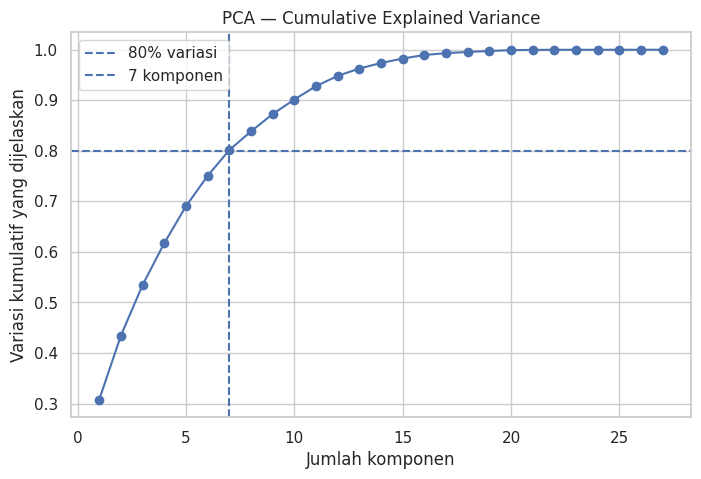

Variasi yang dijelaskan dua komponen: 0.43419953557268104


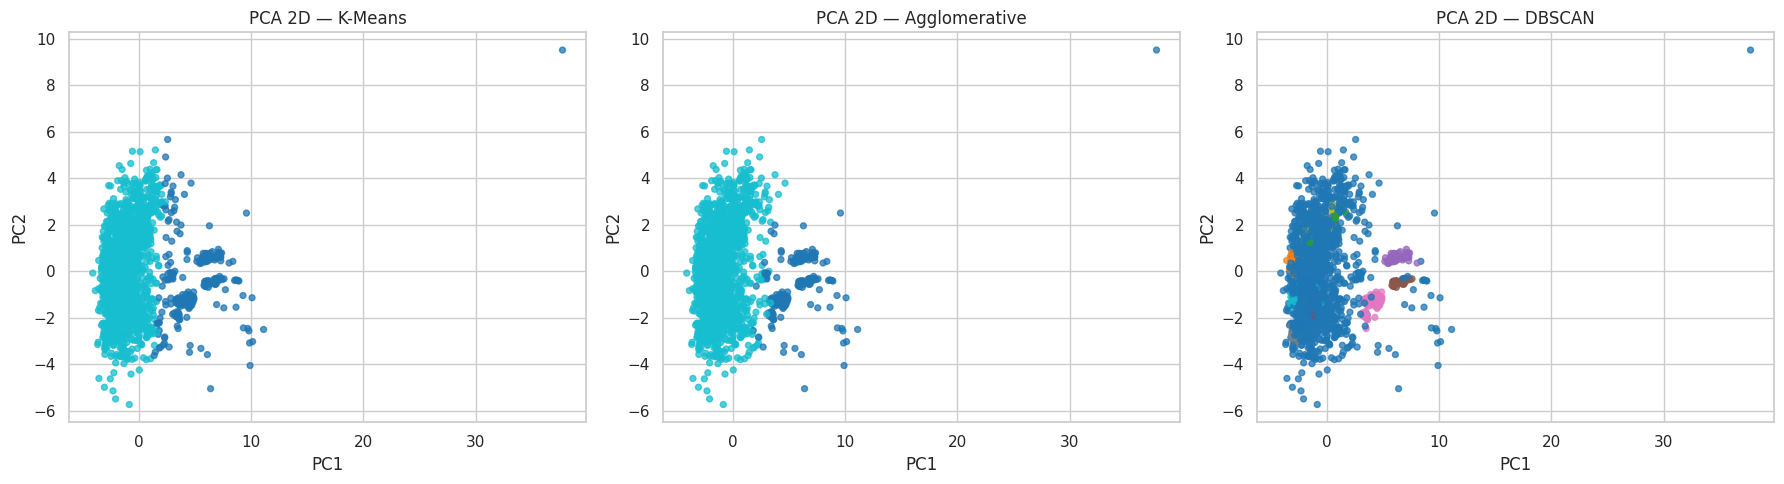

In [11]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
components_80 = int(np.argmax(cumulative_variance >= 0.80) + 1)
print("Jumlah komponen untuk mencapai >=80% variasi:", components_80)
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker="o")
plt.axhline(0.80, linestyle="--", label="80% variasi")
plt.axvline(components_80, linestyle="--", label=f"{components_80} komponen")
plt.xlabel("Jumlah komponen")
plt.ylabel("Variasi kumulatif yang dijelaskan")
plt.title("PCA — Cumulative Explained Variance")
plt.legend()
plt.show()
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_scaled)
print("Variasi yang dijelaskan dua komponen:", pca_2d.explained_variance_ratio_.sum())
label_sets = {"K-Means": labels_kmeans, "Agglomerative": labels_agg, "DBSCAN": labels_dbscan}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, labels) in zip(axes, label_sets.items()):
    ax.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=labels, cmap="tab10", s=18, alpha=0.75)
    ax.set_title(f"PCA 2D — {name}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()


**Penjelasan:** PCA mereduksi dimensi dengan mempertahankan variasi sebanyak mungkin. `components_80` menunjukkan jumlah komponen minimum untuk menjelaskan setidaknya 80% variasi. Plot 2D hanya menampilkan dua komponen pertama.

## 12. Interpretasi dan kesimpulan

In [12]:
print("Ringkasan evaluasi:")
display(comparison.round(4))
print("Distribusi cluster:")
for name, labels in label_sets.items():
    print(chr(10), name)
    display(pd.Series(labels, name="cluster").value_counts().sort_index().rename("jumlah_data"))
profile_data = X_imputed.copy()
profile_data["cluster"] = labels_kmeans
means = profile_data.groupby("cluster")[X_imputed.columns].mean()
feature_ranges = (means.max(axis=0) - means.min(axis=0)).sort_values(ascending=False)
print("10 fitur dengan rentang rata-rata terbesar antar-cluster K-Means:")
display(feature_ranges.head(10).rename("rentang_rata_rata"))
valid_silhouette = comparison["silhouette"].dropna()
if not valid_silhouette.empty:
    print("Silhouette tertinggi pada evaluasi ini:", valid_silhouette.idxmax())
else:
    print("Silhouette tidak dapat dihitung untuk hasil yang tersedia.")
print("Panduan: periksa fitur pembeda, distribusi cluster, dan proporsi noise DBSCAN. Jangan mengartikan cluster sebagai jenis fault tanpa validasi. Label fault hanya dianalisis setelah clustering.")


Ringkasan evaluasi:


,jumlah_cluster,silhouette,davies_bouldin,calinski_harabasz,noise_percent
K-Means,2.0,0.3032,1.2806,569.0076,0.0000
Agglomerative,2.0,0.3098,1.1809,552.0269,0.0000
DBSCAN,15.0,0.5482,0.7441,498.1440,74.0855


Distribusi cluster:

 K-Means


cluster
0     390
1    1551
Name: jumlah_data, dtype: int64


 Agglomerative


...


 DBSCAN


cluster
-1     1438
 0       14
 1       33
 2       20
 3       28
 4       12
 5       11
 6       64
 7       34
 8      173
 9       13
 10      21
 11      19
 12      17
 13      28
 14      16
Name: jumlah_data, dtype: int64

10 fitur dengan rentang rata-rata terbesar antar-cluster K-Means:


Sum_of_Luminosity        882207.993047
Y_Maximum                222824.874468
Y_Minimum                222697.504087
Pixels_Areas               8072.650796
X_Minimum                   586.025616
X_Maximum                   431.667490
X_Perimeter                 398.338228
Y_Perimeter                 255.649750
Length_of_Conveyer           88.684496
Minimum_of_Luminosity        47.670605
Name: rentang_rata_rata, dtype: float64

Silhouette tertinggi pada evaluasi ini: DBSCAN
Panduan: periksa fitur pembeda, distribusi cluster, dan proporsi noise DBSCAN. Jangan mengartikan cluster sebagai jenis fault tanpa validasi. Label fault hanya dianalisis setelah clustering.


**Penjelasan:** Gunakan metrik, distribusi cluster, dan profil fitur untuk membuat kesimpulan berdasarkan hasil aktual.

**Isi kesimpulan setelah menjalankan notebook:**
- Metode paling sesuai berdasarkan metrik dan interpretasi: …
- Jumlah cluster dan pola utama: …
- Fitur pembeda utama: …
- Proporsi noise DBSCAN dan implikasinya: …
- Keterbatasan: hasil dipengaruhi preprocessing, skala, parameter, dan PCA; cluster tidak otomatis sama dengan kategori fault.